# Assignment 2 — Text Classification with TF-IDF and Logistic Regression

## IMDb Movie Review Sentiment Classification

**Objective:** Build a text classification model using **TF-IDF** and **Logistic Regression** to classify IMDb movie reviews as positive or negative.

### Required tasks
1. Load and explore the dataset.
2. Perform text preprocessing.
3. Split the data into training and testing sets.
4. Convert text into numerical features using TF-IDF.
5. Train a Logistic Regression classifier.
6. Predict sentiment on the test set.
7. Evaluate using Accuracy, Precision, Recall, F1-score, and a Confusion Matrix.


## 1. Import the Required Libraries

The notebook uses pandas for data handling, regular expressions for text cleaning, scikit-learn for TF-IDF and Logistic Regression, and matplotlib for visualizations.

In [4]:
import os
import re
import zipfile
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load the IMDb Dataset

The original dataset contains two columns:

- `review`: the movie review text
- `sentiment`: the target label (`positive` or `negative`)

### File path
If you run this notebook on your own computer, change `DATA_PATH` to the location of your dataset.

The loader below supports:
- `.csv`
- `.xlsx` / `.xls`
- `.zip` containing a CSV or Excel file

If the file is in the same folder as this notebook, you can simply use its filename.

In [5]:
# Change this path if your dataset is stored somewhere else.
DATA_PATH = "IMDB Dataset.csv"

def load_imdb_dataset(path):
    if not os.path.exists(path):
        raise FileNotFoundError(
            f"Dataset not found at: {path}\n"
            "Please update DATA_PATH to the location of your IMDb dataset."
        )

    lower_path = path.lower()

    if lower_path.endswith(".csv"):
        return pd.read_csv(path)

    if lower_path.endswith((".xlsx", ".xls")):
        return pd.read_excel(path)

    if lower_path.endswith(".zip"):
        with zipfile.ZipFile(path, "r") as z:
            data_files = [
                name for name in z.namelist()
                if name.lower().endswith((".csv", ".xlsx", ".xls"))
            ]

            if not data_files:
                raise ValueError("The ZIP file does not contain a CSV or Excel dataset.")

            selected_file = data_files[0]

            if selected_file.lower().endswith(".csv"):
                with z.open(selected_file) as f:
                    return pd.read_csv(f)
            else:
                with z.open(selected_file) as f:
                    return pd.read_excel(f)

    raise ValueError("Unsupported file type. Use CSV, Excel, or ZIP.")

df = load_imdb_dataset(DATA_PATH)

print(f"Dataset shape: {df.shape}")
df.head()

Dataset shape: (50000, 2)


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


## 3. Explore the Dataset

In [6]:
print("Columns:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nSentiment counts:")
print(df["sentiment"].value_counts())

Columns:
['review', 'sentiment']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   review     50000 non-null  str  
 1   sentiment  50000 non-null  str  
dtypes: str(2)
memory usage: 63.6 MB

Missing values:
review       0
sentiment    0
dtype: int64

Duplicate rows:
418

Sentiment counts:
sentiment
positive    25000
negative    25000
Name: count, dtype: int64


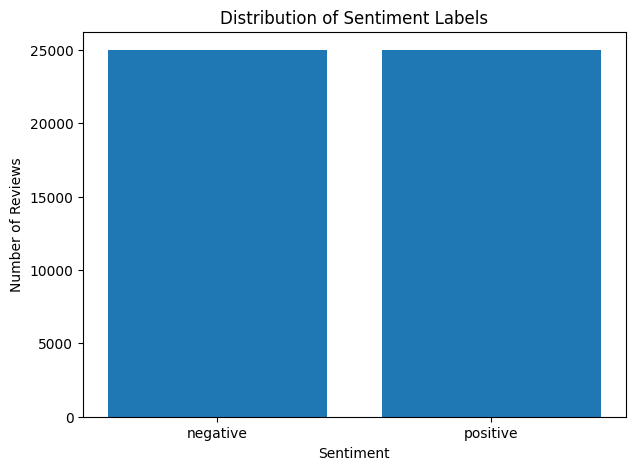

In [7]:
sentiment_counts = df["sentiment"].value_counts().reindex(["negative", "positive"])

plt.figure(figsize=(7, 5))
plt.bar(sentiment_counts.index, sentiment_counts.values)
plt.title("Distribution of Sentiment Labels")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.show()

## 4. Clean the Dataset

The reviews contain HTML line-break tags such as `<br />`. The preprocessing function:

- converts text to lowercase
- removes HTML line-break tags
- removes URLs
- removes non-letter characters
- removes extra whitespace

This keeps the text suitable for TF-IDF vectorization.

In [8]:
# Keep only the required columns
df = df[["review", "sentiment"]].copy()

# Remove rows with missing values
df = df.dropna(subset=["review", "sentiment"])

# Remove duplicate rows
df = df.drop_duplicates().reset_index(drop=True)

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"<br\s*/?>", " ", text)
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"[^a-zA-Z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["clean_review"] = df["review"].apply(clean_text)

print("Dataset shape after cleaning:", df.shape)
display(df[["review", "clean_review", "sentiment"]].head())

Dataset shape after cleaning: (49582, 3)


,review,clean_review,sentiment
0,One of the other reviewers has mentioned that ...,one of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,a wonderful little production the filming tech...,positive
2,I thought this was a wonderful way to spend ti...,i thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,basically there s a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",petter mattei s love in the time of money is a...,positive


## 5. Encode the Sentiment Labels

Logistic Regression requires numerical target labels.

- `negative` → 0
- `positive` → 1

In [9]:
label_map = {"negative": 0, "positive": 1}
df["label"] = df["sentiment"].map(label_map)

if df["label"].isnull().any():
    raise ValueError("Unexpected sentiment label found in the dataset.")

print(df["label"].value_counts().sort_index())
display(df[["sentiment", "label"]].drop_duplicates().sort_values("label"))

label
0    24698
1    24884
Name: count, dtype: int64


,sentiment,label
3,negative,0
0,positive,1


## 6. Split the Data into Training and Testing Sets

The dataset is split into:

- **80% training data**
- **20% testing data**

`stratify=y` keeps the positive/negative class distribution approximately the same in both sets.

In [10]:
X = df["clean_review"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 39665
Testing samples: 9917


## 7. Convert Text to Numerical Features Using TF-IDF

TF-IDF (Term Frequency–Inverse Document Frequency) converts the text into numerical feature vectors.

The vectorizer below uses:
- unigrams and bigrams (`ngram_range=(1, 2)`)
- English stop-word removal
- a maximum of 50,000 features
- sublinear TF scaling

In [11]:
tfidf = TfidfVectorizer(
    stop_words="english",
    ngram_range=(1, 2),
    max_features=50000,
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (39665, 50000)
Testing TF-IDF shape: (9917, 50000)


## 8. Train the Logistic Regression Classifier

In [12]:
model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

model.fit(X_train_tfidf, y_train)

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


## 9. Predict the Sentiment of the Test Data

In [13]:
y_pred = model.predict(X_test_tfidf)

print("Predictions generated successfully.")
print("First 20 predictions:", y_pred[:20])

Predictions generated successfully.
First 20 predictions: [0 1 1 0 0 1 0 0 1 0 0 1 1 0 1 1 1 0 1 0]


## 10. Evaluate the Model

The assignment requires:

- Accuracy
- Precision
- Recall
- F1-score
- Confusion Matrix

In [14]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Negative", "Positive"]
    )
)

Accuracy : 0.8998
Precision: 0.8884
Recall   : 0.9152
F1-score : 0.9016

Classification Report:
              precision    recall  f1-score   support

    Negative       0.91      0.88      0.90      4940
    Positive       0.89      0.92      0.90      4977

    accuracy                           0.90      9917
   macro avg       0.90      0.90      0.90      9917
weighted avg       0.90      0.90      0.90      9917



## 11. Confusion Matrix

The confusion matrix shows:

- **True Negative (TN):** negative reviews correctly classified
- **False Positive (FP):** negative reviews classified as positive
- **False Negative (FN):** positive reviews classified as negative
- **True Positive (TP):** positive reviews correctly classified

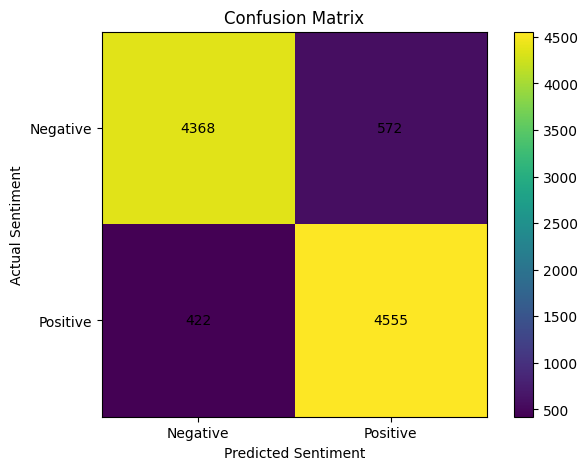

In [15]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))
plt.imshow(cm, interpolation="nearest")
plt.title("Confusion Matrix")
plt.colorbar()
plt.xticks([0, 1], ["Negative", "Positive"])
plt.yticks([0, 1], ["Negative", "Positive"])
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.show()

## 12. Visualize the Evaluation Metrics

,Metric,Score
0,Accuracy,0.899768
1,Precision,0.888434
2,Recall,0.915210
3,F1-score,0.901623


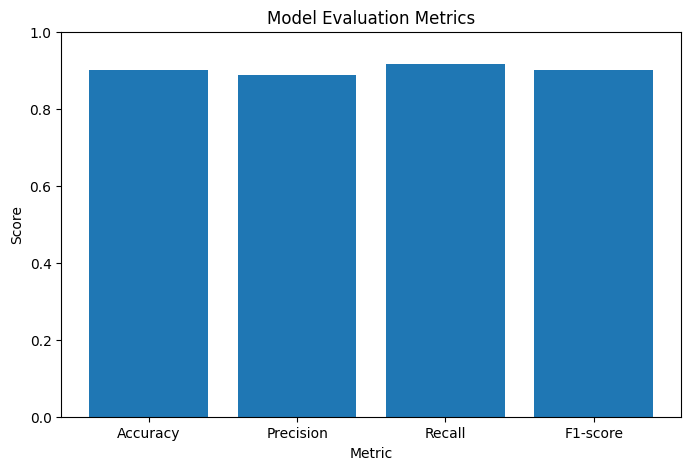

In [16]:
metrics = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Score": [accuracy, precision, recall, f1]
})

display(metrics)

plt.figure(figsize=(8, 5))
plt.bar(metrics["Metric"], metrics["Score"])
plt.ylim(0, 1)
plt.title("Model Evaluation Metrics")
plt.xlabel("Metric")
plt.ylabel("Score")
plt.show()

## 13. Test the Model with New Reviews

The trained model can also classify reviews that were not part of the dataset.

In [17]:
new_reviews = [
    "This movie was absolutely amazing. I loved every minute of it.",
    "The movie was boring, poorly written, and a complete waste of time.",
    "The acting was excellent and the story was very enjoyable.",
    "I did not enjoy this movie at all. It was disappointing."
]

new_reviews_clean = [clean_text(review) for review in new_reviews]
new_reviews_tfidf = tfidf.transform(new_reviews_clean)

new_predictions = model.predict(new_reviews_tfidf)
new_probabilities = model.predict_proba(new_reviews_tfidf).max(axis=1)

results = pd.DataFrame({
    "Review": new_reviews,
    "Predicted Sentiment": [
        "Positive" if pred == 1 else "Negative"
        for pred in new_predictions
    ],
    "Confidence": new_probabilities
})

display(results)

,Review,Predicted Sentiment,Confidence
0,This movie was absolutely amazing. I loved eve...,Positive,0.900134
1,"The movie was boring, poorly written, and a co...",Negative,0.998132
2,The acting was excellent and the story was ver...,Positive,0.966847
3,I did not enjoy this movie at all. It was disa...,Negative,0.864836


## 14. Conclusion

The IMDb movie reviews were classified using a complete text-classification pipeline:

**Raw Reviews → Text Preprocessing → Train/Test Split → TF-IDF → Logistic Regression → Predictions → Evaluation**

The final model was evaluated using Accuracy, Precision, Recall, F1-score, and a Confusion Matrix as required.